### Detecção de linhas de plantio
#### PGC111 - Grupo D

---

#### Descrição

Aqui vamos apresentar os conceitos que foram utilizados neste trabalho. O objetivo é  "preparar o terreno" antes de mostrar a pipeline proposta.

---

In [ ]:
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd


**As imagens**:

São imagens de uma plantação de feijão (drybean). Fotografadas em 25/06/2020 com uma câmera multiespectral MicaSense RedEdge, a 20–30 m de altura, com resolução no solo (GSD) de cerca de 12 a 18 mm por pixel.

Referência:
From RGB to NIR: Predicting of Near Infrared Reflectance from Visible Spectrum Aerial Images of Crops* (ICCV Workshops, CVPPA).

In [ ]:
def ler_imagem(caminho, flag=cv2.IMREAD_COLOR):
    """Lê uma imagem (funciona com acentos no caminho, no Windows)."""
    dados = np.fromfile(str(caminho), dtype=np.uint8)
    img = cv2.imdecode(dados, flag)
    if img is None:
        raise FileNotFoundError(f"Não foi possível ler {caminho}")
    return img

def ler_rgb(caminho):
    """Imagem colorida em RGB (o OpenCV lê em BGR)."""
    return cv2.cvtColor(ler_imagem(caminho), cv2.COLOR_BGR2RGB)

def ler_nir(caminho):
    """Banda do infravermelho próximo (NIR), em tons de cinza.
    O arquivo tem 3 canais iguais; IMREAD_GRAYSCALE lê um só."""
    return ler_imagem(caminho, cv2.IMREAD_GRAYSCALE)

RGB: (798, 1098, 3) -> altura, largura e 3 canais (vermelho, verde, azul)
NIR: (799, 1099) -> altura e largura (um único canal, em tons de cinza)


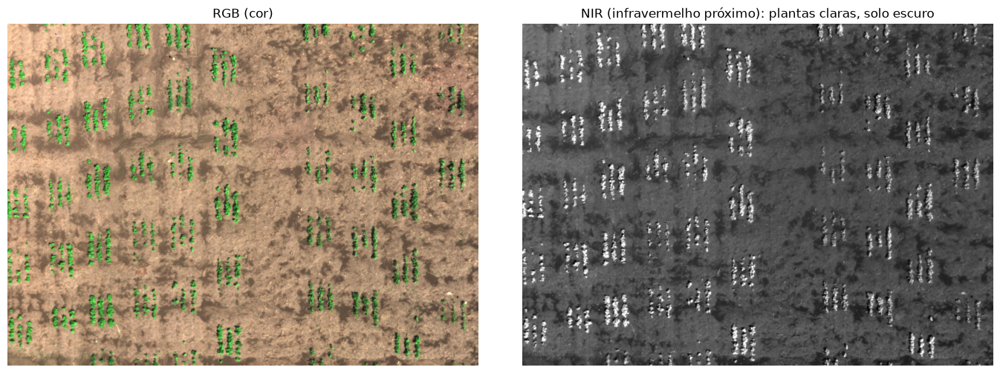

In [ ]:
## Mostrar uma imagem RGB e o seu par NIR
pasta = Path("imagens/drybean-estagio-inicial")
id_img = 209   # número da imagem: o par RGB e NIR tem o mesmo número

rgb = ler_rgb(pasta / "RGB-1" / f"{id_img}.png")
nir = ler_nir(pasta / "NIR-1" / f"{id_img}.png")

print("RGB:", rgb.shape, "-> altura, largura e 3 canais (vermelho, verde, azul)")
print("NIR:", nir.shape, "-> altura e largura (um único canal, em tons de cinza)")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(rgb)
ax[0].set_title("RGB (cor)")
ax[1].imshow(nir, cmap="gray")
ax[1].set_title("NIR (infravermelho próximo): plantas claras, solo escuro")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

---

**Índice de vegetação**

Fórmula que transforma os 3 canais (rgb) em um único número, para escala de cinza. A clorofila (plantas) absorve muita luz vermelha e azul e usa essa energia na fotossíntese. A luz verde é refletida, por isso a planta parece verde. O solo, por exemplo rico em óxido e ferro, reflete mais vermelho. Então na planta, G é alto e R e B é baixo. No solo, R é alto em relação a G. Então na prática, converte a imagem rgb para cinza onde a vegetação aparece clara. Isso dá espaço para binarização.

**Índice ExG (Excess Green)**

$ExG=2g-r-b$

O verde menos a média dos outros dois. Produz uma reta horizontal. Acima dela é planta, abaixo é solo. Atribui um peso maior para o verde (multiplica por dois) e subtrai vermelho e azul. Assumimos que o verde já é alto na imagem, ou seja o resultado será um positivo alto quando for planta.

ExG vai de -0.2 a 0.87


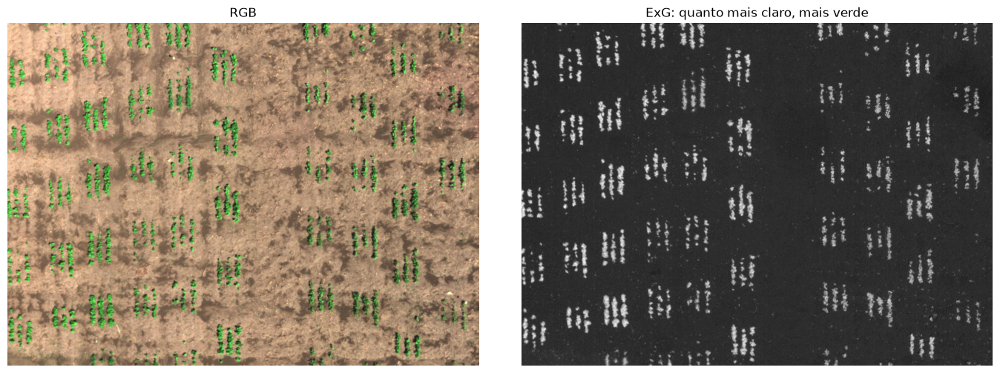

In [ ]:
## Índice ExG na mesma imagem
# 1) Separar os 3 canais e converter para números reais (para as divisões darem certo)
R = rgb[:, :, 0].astype(float)
G = rgb[:, :, 1].astype(float)
B = rgb[:, :, 2].astype(float)

# 2) Normalizar: dividir cada canal pela soma dos três (tira o efeito do brilho/sombra)
soma = R + G + B + 1e-6   # o 1e-6 evita divisão por zero em pixels pretos
r, g, b = R / soma, G / soma, B / soma

# 3) ExG = 2g - r - b: quanto o verde se destaca dos outros dois canais
exg = 2 * g - r - b

print("ExG vai de", round(exg.min(), 2), "a", round(exg.max(), 2))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(rgb)
ax[0].set_title("RGB")
ax[1].imshow(exg, cmap="gray")
ax[1].set_title("ExG: quanto mais claro, mais verde")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

**Índice ExGR**

Primeiro define o $ExR$ (excess red).\
$ExR=1,4r-g$\
O índice final é:\
$ExGR=ExG-ExR$\
Quanto parece planta menos quanto parece solo. A intuição é: $ExGR>0=Planta$. É uma maneira de limiarizar.

ExGR vai de -0.56 a 1.2


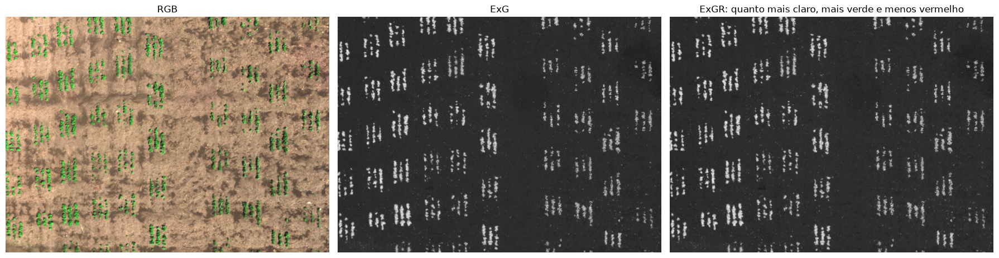

In [ ]:
## Índice ExGR na mesma imagem (usa r, g, b e exg da célula anterior)
# 1) ExR (Excess Red): quanto o vermelho se destaca -> alto no solo
exr = 1.4 * r - g

# 2) ExGR = ExG - ExR: "quanto parece planta" menos "quanto parece solo"
exgr = exg - exr

print("ExGR vai de", round(exgr.min(), 2), "a", round(exgr.max(), 2))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].imshow(rgb)
ax[0].set_title("RGB")
ax[1].imshow(exg, cmap="gray")
ax[1].set_title("ExG")
ax[2].imshow(exgr, cmap="gray")
ax[2].set_title("ExGR: quanto mais claro, mais verde e menos vermelho")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

**Normalized Difference Vegetation Index (NDVI)**

$NDVI=\frac{NIR-RED}{NIR+RED}$

A planta absorver toda luz vermelha como fonte de energia, mas o near infrared ela reflete. Quanto maior a diferença entre as duas, mais forte será a cor branca na imagem (vegetação). A divisão pela soma dos dois produz um valor normalizado [-1, +1].

NDVI vai de -0.4 a 0.62


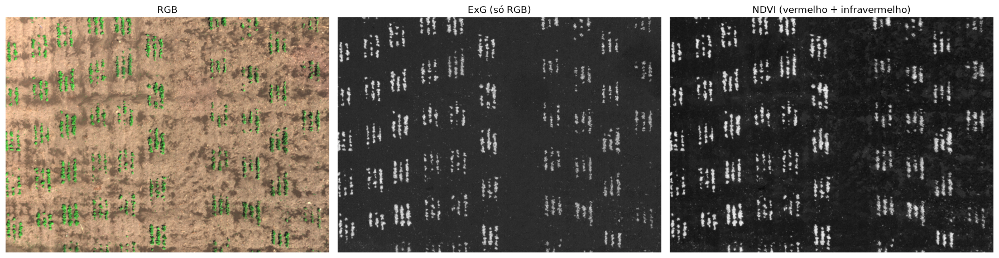

In [ ]:
## NDVI na mesma imagem (usa rgb e nir da primeira célula)
# 1) Deixar o NIR do mesmo tamanho da RGB (o NIR tem 1 pixel a mais em cada direção)
nir_ajustado = nir[:rgb.shape[0], :rgb.shape[1]]

# 2) Vermelho (R) e infravermelho (NIR) como números reais
R = rgb[:, :, 0].astype(float)
N = nir_ajustado.astype(float)

# 3) NDVI = (NIR - R) / (NIR + R): a planta reflete muito NIR e pouco vermelho
ndvi = (N - R) / (N + R + 1e-6)   # o 1e-6 evita divisão por zero

print("NDVI vai de", round(ndvi.min(), 2), "a", round(ndvi.max(), 2))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].imshow(rgb)
ax[0].set_title("RGB")
ax[1].imshow(exg, cmap="gray")
ax[1].set_title("ExG (só RGB)")
ax[2].imshow(ndvi, cmap="gray")
ax[2].set_title("NDVI (vermelho + infravermelho)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

**Abordagem que podemos utilizar**:
ExG + OTSU. Combinamos algum índice com a técnica de limiarização para obter uma imagem binária

Limiar escolhido pelo Otsu: 103.0 (numa escala de 0 a 255)
Pixels marcados como planta: 6.7%


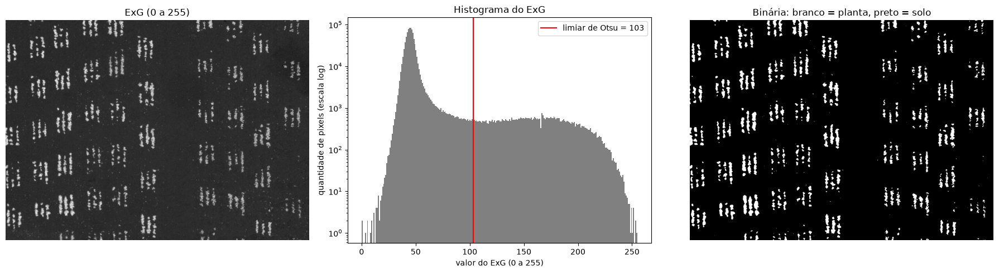

In [ ]:
## ExG + Otsu: transformar a imagem em tons de cinza numa imagem binária (planta x solo)
# 1) O Otsu do OpenCV só aceita imagens de 8 bits (inteiros de 0 a 255):
#    reescalamos o ExG para essa faixa (menor valor -> 0, maior valor -> 255)
exg_255 = (exg - exg.min()) / (exg.max() - exg.min()) * 255
exg_255 = exg_255.astype(np.uint8)

# 2) Otsu: escolhe sozinho o limiar que melhor separa os dois "montes" do histograma
limiar, binaria = cv2.threshold(exg_255, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
# binaria: 255 (branco) onde exg_255 > limiar (planta) e 0 (preto) no resto (solo)

print("Limiar escolhido pelo Otsu:", limiar, "(numa escala de 0 a 255)")
print(f"Pixels marcados como planta: {(binaria == 255).mean():.1%}")

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].imshow(exg_255, cmap="gray")
ax[0].set_title("ExG (0 a 255)")
ax[1].hist(exg_255.ravel(), bins=256, range=(0, 255), color="gray")
ax[1].axvline(limiar, color="red", label=f"limiar de Otsu = {limiar:.0f}")
ax[1].set_yscale("log")   # escala log: o monte do solo é muito maior que o das plantas
ax[1].set_xlabel("valor do ExG (0 a 255)")
ax[1].set_ylabel("quantidade de pixels (escala log)")
ax[1].set_title("Histograma do ExG")
ax[1].legend()
ax[2].imshow(binaria, cmap="gray")
ax[2].set_title("Binária: branco = planta, preto = solo")
ax[0].axis("off")
ax[2].axis("off")
plt.tight_layout()
plt.show()

---

**Mas como medir a qualidade? Precisamos de imagens anotadas**

As imagens anotadas fornecem uma referência dos pontos onde as linhas de plantio devem ser detectadas e também as falhas nessas linhas.

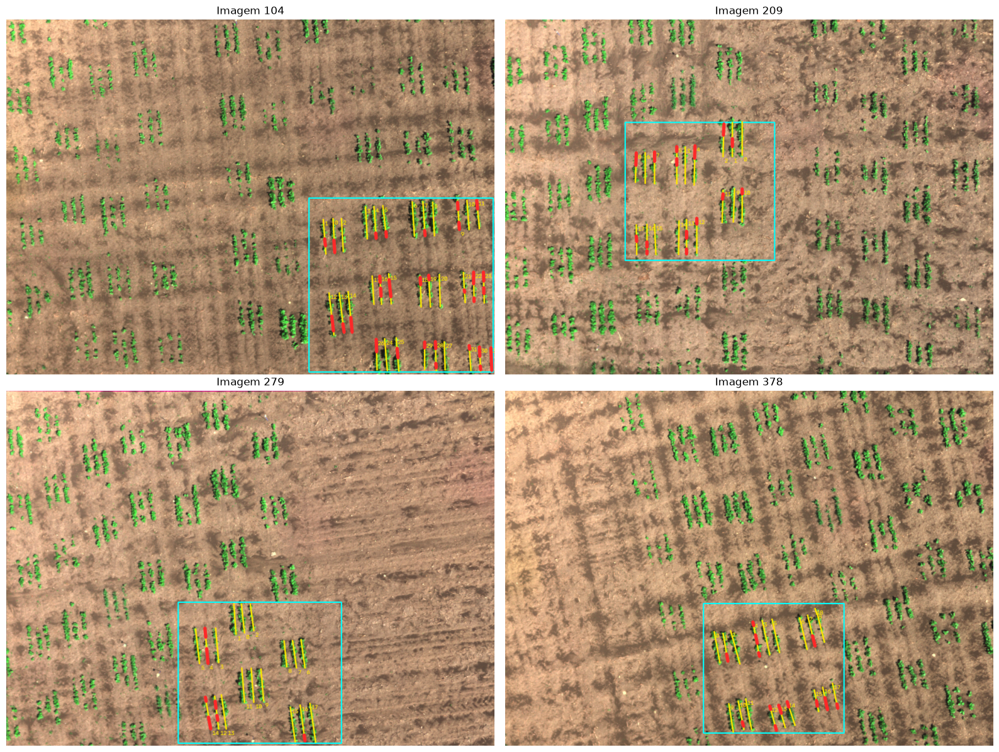

In [ ]:
## Quatro imagens anotadas como exemplo
# As anotações foram feitas à mão com a ferramenta ferramentas/anotar_feijao.py.
# Ciano = região anotada | amarelo = linhas de plantio | vermelho = falhas
pasta_anotadas = Path("imagens/drybean-estagio-inicial/anotadas")
exemplos = [104, 209, 279, 378]   # a 378 tem as linhas inclinadas

fig, ax = plt.subplots(2, 2, figsize=(16, 12))
for a, id_img in zip(ax.ravel(), exemplos):
    a.imshow(ler_rgb(pasta_anotadas / f"{id_img}.png"))
    a.set_title(f"Imagem {id_img}")
    a.axis("off")
plt.tight_layout()
plt.show()

---

**Limpando imagens e consolidando linhas**

As imagens possuem ruídos. E as linhas precisam ser consolidadas. Para isso vamos trabalhar com morfologia. Aplicamos um elemento estruturante para cada caso.

Elemento estruturante (disco 3 x 3):
[[0 1 0]
 [1 1 1]
 [0 1 0]]
Pixels de ruído removidos: 2073


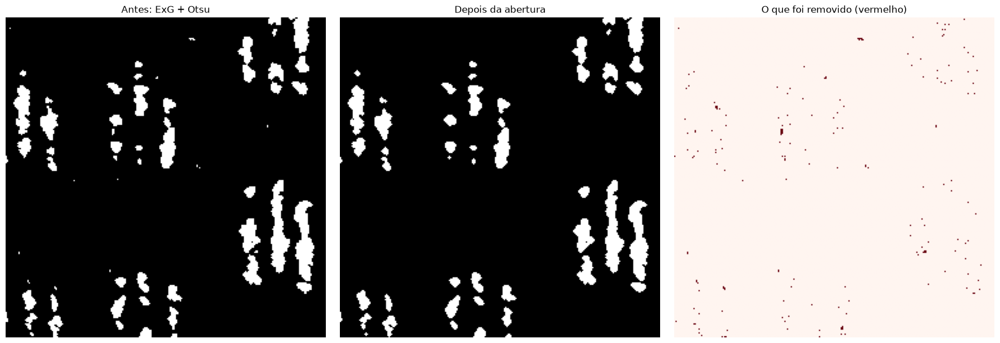

In [ ]:
## 1) Remover ruídos: abertura com um disco de 3 px (o mesmo do notebook principal)
# Abertura = erosão seguida de dilatação: apaga manchas brancas menores que o disco
# e devolve às plantas (maiores) o tamanho original.
disco = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
print("Elemento estruturante (disco 3 x 3):")
print(disco)

limpa = cv2.morphologyEx(binaria, cv2.MORPH_OPEN, disco)

removidos = (binaria == 255) & (limpa == 0)
print(f"Pixels de ruído removidos: {removidos.sum()}")

# Zoom em um pedaço da imagem para ver o efeito
y, x, t = 250, 300, 250
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(binaria[y:y + t, x:x + t], cmap="gray")
ax[0].set_title("Antes: ExG + Otsu")
ax[1].imshow(limpa[y:y + t, x:x + t], cmap="gray")
ax[1].set_title("Depois da abertura")
ax[2].imshow(removidos[y:y + t, x:x + t], cmap="Reds")
ax[2].set_title("O que foi removido (vermelho)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

Elemento estruturante vertical: (13, 1) (13 linhas x 1 coluna)


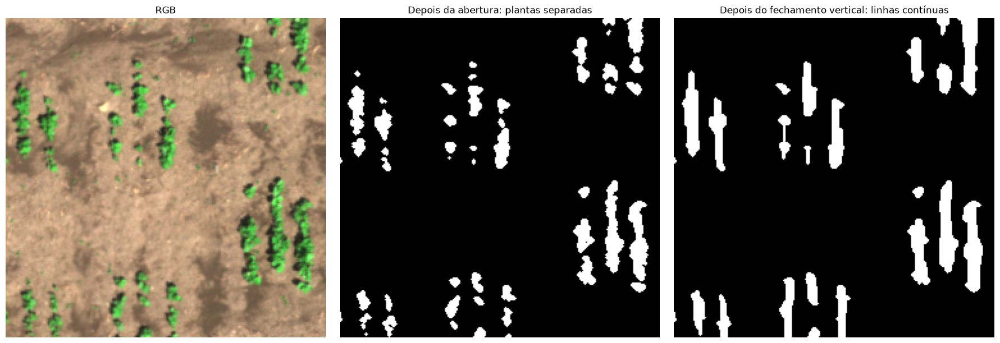

In [ ]:
## 2) Consolidar as linhas: fechamento com um elemento vertical de 1 x 13 px (o do notebook principal)
# Fechamento = dilatação seguida de erosão: preenche os espaços pretos menores que o elemento.
# Por ser vertical (na direção das linhas), emenda as plantas de uma mesma linha
# sem grudar as linhas vizinhas, que ficam a ~20 px para o lado.
vertical = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 13))
print("Elemento estruturante vertical:", vertical.shape, "(13 linhas x 1 coluna)")

consolidada = cv2.morphologyEx(limpa, cv2.MORPH_CLOSE, vertical)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(rgb[y:y + t, x:x + t])
ax[0].set_title("RGB")
ax[1].imshow(limpa[y:y + t, x:x + t], cmap="gray")
ax[1].set_title("Depois da abertura: plantas separadas")
ax[2].imshow(consolidada[y:y + t, x:x + t], cmap="gray")
ax[2].set_title("Depois do fechamento vertical: linhas contínuas")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

---

**A direção (ângulo) e a posição das linhas** são informações que fazem parte da detecção. Aqui dois métodos podem ser mencionados:
- Projeções
- Transformada de Hough

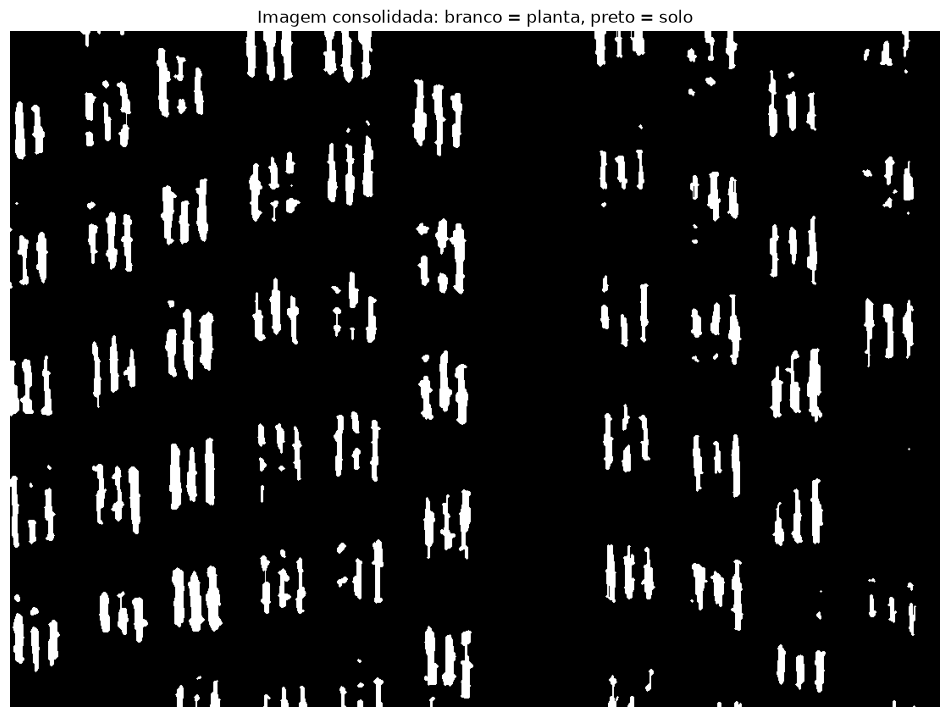

In [ ]:
## Imagem utilizada
plt.figure(figsize=(12, 9))
plt.imshow(consolidada, cmap="gray")
plt.title("Imagem consolidada: branco = planta, preto = solo")
plt.axis("off")
plt.show()

Ângulo das linhas encontrado pelas projeções: 89 graus


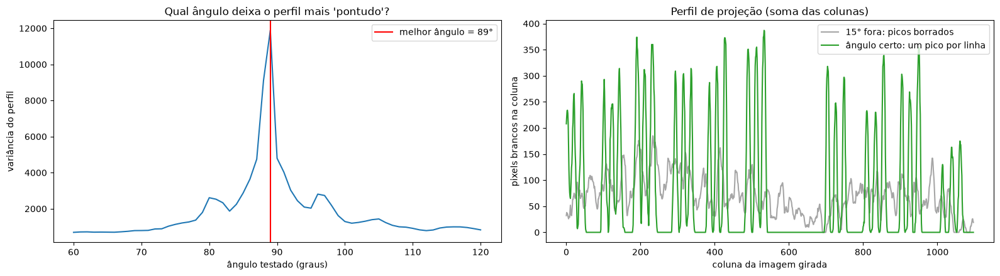

In [ ]:
## Projeções: girar a imagem e somar os pixels brancos de cada coluna
# Usa a imagem 'consolidada' (depois da abertura e do fechamento).
# No ângulo certo, as linhas ficam em pé: a soma das colunas tem picos altos e vales fundos.
h, w = consolidada.shape
centro = (w / 2, h / 2)

angulos = np.arange(60, 121, 1)   # ângulos testados (90 = linha vertical)
variancias = []
for a in angulos:
    M = cv2.getRotationMatrix2D(centro, a - 90, 1.0)    # gira para a linha de ângulo 'a' ficar em pé
    girada = cv2.warpAffine(consolidada, M, (w, h))
    perfil = (girada > 0).sum(axis=0)                   # quantos pixels brancos em cada coluna
    variancias.append(perfil.var())                     # perfil "pontudo" = variância alta

melhor = angulos[np.argmax(variancias)]
print("Ângulo das linhas encontrado pelas projeções:", melhor, "graus")

# Perfil no ângulo certo x 15 graus fora
M_certo = cv2.getRotationMatrix2D(centro, melhor - 90, 1.0)
M_errado = cv2.getRotationMatrix2D(centro, melhor + 15 - 90, 1.0)
perfil_certo = (cv2.warpAffine(consolidada, M_certo, (w, h)) > 0).sum(axis=0)
perfil_errado = (cv2.warpAffine(consolidada, M_errado, (w, h)) > 0).sum(axis=0)

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
ax[0].plot(angulos, variancias)
ax[0].axvline(melhor, color="red", label=f"melhor ângulo = {melhor}°")
ax[0].set_xlabel("ângulo testado (graus)")
ax[0].set_ylabel("variância do perfil")
ax[0].set_title("Qual ângulo deixa o perfil mais 'pontudo'?")
ax[0].legend()
ax[1].plot(perfil_errado, color="gray", alpha=0.7, label="15° fora: picos borrados")
ax[1].plot(perfil_certo, color="tab:green", label="ângulo certo: um pico por linha")
ax[1].set_xlabel("coluna da imagem girada")
ax[1].set_ylabel("pixels brancos na coluna")
ax[1].set_title("Perfil de projeção (soma das colunas)")
ax[1].legend()
plt.tight_layout()
plt.show()

Segmentos encontrados: 1229
Ângulo das linhas (mediana dos segmentos): 90.0 graus


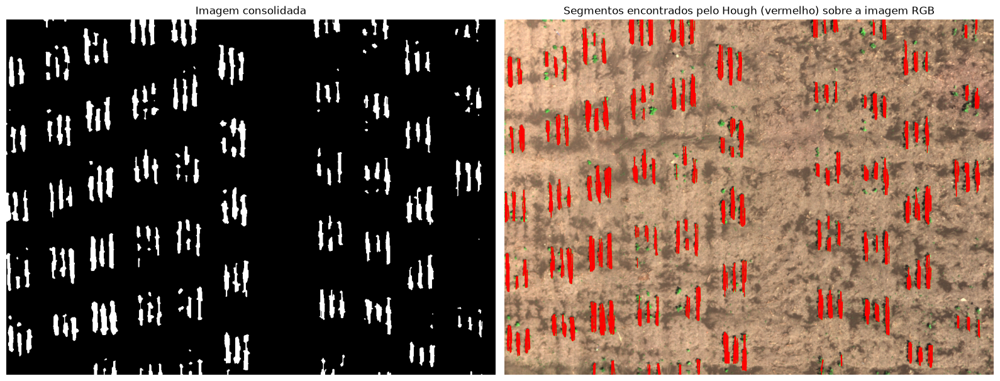

In [ ]:
## Transformada de Hough: cada pixel branco "vota" nas retas que passam por ele
# Usamos a versão probabilística (HoughLinesP), que devolve SEGMENTOS de reta.
# Um segmento é aceito se tiver pelo menos 20 votos, pelo menos 20 px de comprimento
# e nenhum vão maior que 5 px (os mesmos valores do notebook principal).
segmentos = cv2.HoughLinesP(consolidada, rho=1, theta=np.radians(0.5), threshold=20,
                            minLineLength=20, maxLineGap=5)
segmentos = segmentos.reshape(-1, 4)          # cada linha: x1, y1, x2, y2
print("Segmentos encontrados:", len(segmentos))

# Ângulo de cada segmento (90 = vertical); ficamos só com os quase verticais (60 a 120 graus)
dx = segmentos[:, 2] - segmentos[:, 0]
dy = segmentos[:, 3] - segmentos[:, 1]
angulos_seg = np.degrees(np.arctan2(dy, dx)) % 180
quase_verticais = (angulos_seg >= 60) & (angulos_seg <= 120)
print("Ângulo das linhas (mediana dos segmentos):", round(np.median(angulos_seg[quase_verticais]), 1), "graus")

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].imshow(consolidada, cmap="gray")
ax[0].set_title("Imagem consolidada")
ax[1].imshow(rgb)
for x1, y1, x2, y2 in segmentos[quase_verticais]:
    ax[1].plot([x1, x2], [y1, y2], color="red", lw=1)
ax[1].set_title("Segmentos encontrados pelo Hough (vermelho) sobre a imagem RGB")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()